# 296. Cysteine-framework pilot, Cnidaria: kmerseek `cys2` and `cys_hp3` against phmmer and a cysteine-spacing regex, Swiss-Prot

**Question.** A disulfide-rich peptide is a short secreted peptide (10 to 60 residues here)
held in shape by two or more disulfide bonds. Its cysteine framework is the pattern of
cysteine positions (`C-C-CC-C-C`). Between species the residues between the cysteines
change fast, so phmmer often has too little sequence to align. Does a kmerseek alphabet
that gives cysteine its own letter rank venom toxins from other phyla above non-toxins
better than phmmer does, and better than a regular expression built from the cysteine
spacing alone?

**What this decides.** Whether the full runs are worth their compute: the three-phylum run
of [PR 145](https://github.com/seanome/2024-kmerseek-analysis/pull/145), and the kmerseek
change that would let `cys2` index a full Swiss-Prot. This pilot is too small to give the
experiment's numbers, but it can show whether kmerseek is far behind the two other methods
on the same queries.

**Decision rule.** The measure is how many of a query's top 10 hits are toxins, averaged
over all 59 queries (a query with no hits counts as 0 toxins). Ten entries drawn at random
from this reference hold 2.75 toxins on average, which is the chance level.

- If a kmerseek setting's mean is above phmmer's (E-value 10 or less) **and** above the
  exact regex's, with 95% intervals that do not overlap theirs, the full runs go ahead as
  planned.
- If kmerseek is above chance but below phmmer and the regex, the full runs go ahead only
  for the queries phmmer misses (section 3 says how many there are); the kmerseek side is
  not worth a `cys2` fix on its own.
- If no kmerseek setting is above chance, stop the kmerseek arm.

This rule was written after a first look at the toxin share of all hits per method (the
first column of the table in section 2), not before. The per-query top-10 measure and its
intervals were computed after the rule was written.

**Data.** The pilot run of 2026-10-15 on Sherlock
(`nextflow-runs/cys-frameworks/pilot`, image
`olgabot/kmerseek:2026-10-15-cys-frameworks-c39370c`, kmerseek built from
[seanome/kmerseek `olgabot/cys-runs-040`](https://github.com/seanome/kmerseek/tree/olgabot/cys-runs-040)).

- **Queries:** the 59 mature peptides from Cnidaria (sea anemones, jellyfish, corals) in
  `tables/cys_frameworks/queries.csv`, at most 10 per cysteine framework.
- **Target database:** Swiss-Prot with every Cnidaria entry removed, then sampled: all
  7,581 entries carrying UniProt's Toxin keyword (KW-0800) and 19,989 others, 27,570 in all.
  A hit counts as correct when the target carries the Toxin keyword.
- **Tools, all on the same queries and the same target database:**
  - kmerseek `cys2` (cysteine against everything else) at k 12, 16, 20, 24 and 28, with
    the low-complexity mask, which drops the one k-mer with no cysteine in it;
  - kmerseek `cys_hp3` (cysteine, hydrophobic, polar; `hp_pbotc_1st_ed_hpc3`) at k 9, 11,
    13 and 15, no mask;
  - phmmer, every hit up to E-value 1,000, cut here at 10;
  - the regular expression each query's cysteine spacing implies, exact (slack 0) or with
    each gap allowed to differ by up to 2 residues (slack 2).

**Caveat on scale.** Toxins are 27.5% of this sampled reference but about 1.3% of the full
one (7,581 of about 575,700 entries), so every precision here is far above what the full
run will give. The comparison between tools on the same reference is what this notebook
is for.

The kmerseek hit files are 6 GB; `scripts/reduce_cys_framework_hits.py` cut them on
Sherlock to one row per query and target (Slurm job 48246909, 2026-10-17), and the
notebook reads those tables from `~/data/cys-frameworks/pilot` (or `$CYS_PILOT_DIR`).

In [1]:
import os
import sys
from pathlib import Path

import gzip
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import display

sys.path.insert(0, ".")
import cys_framework_utils as cfu
import hp_conservation_utils as hc
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(160)
pl.Config.set_fmt_str_lengths(60)

DATA = Path(os.environ.get("CYS_PILOT_DIR", Path.home() / "data/cys-frameworks/pilot"))
SWISSPROT = Path.home() / "data/cys-frameworks/uniprot_sprot.fasta.gz"
FIG = Path("../figures")
CLADE = "Cnidaria"
TOP_N = 10
COLOUR = {
    "cys2": pf.OKABE_ITO["blue"],
    "cys_hp3": pf.OKABE_ITO["vermillion"],
    "phmmer": pf.OKABE_ITO["black"],
    "regex slack 0": pf.OKABE_ITO["bluish_green"],
    "regex slack 2": pf.OKABE_ITO["orange"],
    "chance": pf.GREY,
}


def method_colour(m: str) -> str:
    return (
        COLOUR["cys2"]
        if "cys2" in m
        else (
            COLOUR["cys_hp3"]
            if "cys_hp3" in m
            else COLOUR["phmmer"] if "phmmer" in m else COLOUR[m]
        )
    )


def method_rows(methods: list[str]) -> list[float]:
    # y position of each method, top to bottom, with a gap between tool groups.
    group = lambda m: (
        0 if "cys2" in m else 1 if "cys_hp3" in m else 2 if "phmmer" in m else 3
    )
    y, pos = [], 0.0
    for i, m in enumerate(methods):
        if i and group(m) != group(methods[i - 1]):
            pos += 0.8
        y.append(-pos)
        pos += 1
    return y


PHMMER_MAX_EVALUE = 10
SETTINGS = pl.read_csv("../tables/cys_frameworks/settings.csv")

truth = set((DATA / f"phylum.{CLADE}.truth.txt").read_text().split())
reference = set((DATA / f"phylum.{CLADE}.reference_accessions.txt").read_text().split())
queries = pl.read_csv(DATA / "references/query_table.tsv", separator="\t")
base_rate = len(truth & reference) / len(reference)
chance_top_n = TOP_N * base_rate
print(
    f"{queries.height} {CLADE} queries; reference {len(reference):_} entries, "
    f"{len(truth & reference):_} of them toxins ({base_rate:.1%})"
)
print(
    f"chance: {TOP_N} random reference entries hold {chance_top_n:.2f} toxins on average"
)

59 Cnidaria queries; reference 27_570 entries, 7_581 of them toxins (27.5%)
chance: 10 random reference entries hold 2.75 toxins on average


## 1. One ranked hit list per query and tool

Each tool gives each query a list of target proteins. kmerseek ranks a target by its best
region's Poisson score: minus log10 of the chance of that many shared k-mers in the region
if the k-mers matched at random, so bigger is stronger. Ties go to more shared k-mers,
then to the accession. These pilot settings do not extend regions, so kmerseek reports no
E-value (every `region_evalue` is infinite) and the Poisson score is the score it has.
phmmer ranks by E-value, smaller first.

**Ties.** Many targets share the same kmerseek score: in `cys2` k16, the group of targets
tied at rank 10 has a median of 4 members and up to 122. Cutting such a group by accession
would pick an arbitrary part of it. So when a tied group crosses the 10th place, it adds
the number of toxins expected if the tie were broken at random: the places left times the
toxin share of the group. The regex gives an unranked set, which is one big tie, and the
same rule applies to it (all of its hits when it has 10 or fewer). Ties for kmerseek are
on the Poisson score and the shared k-mer count together; for phmmer, on the E-value.

The figure shows, for each tool, the toxin share of every hit it returned, against the
toxin share of the reference (a tool that picked targets at random would sit on the grey
line). The right edge gives how many query-target pairs each tool returned: kmerseek
returns hundreds of times more than phmmer, so its share is over a much deeper list.

toxin share of the reference itself: 0.275


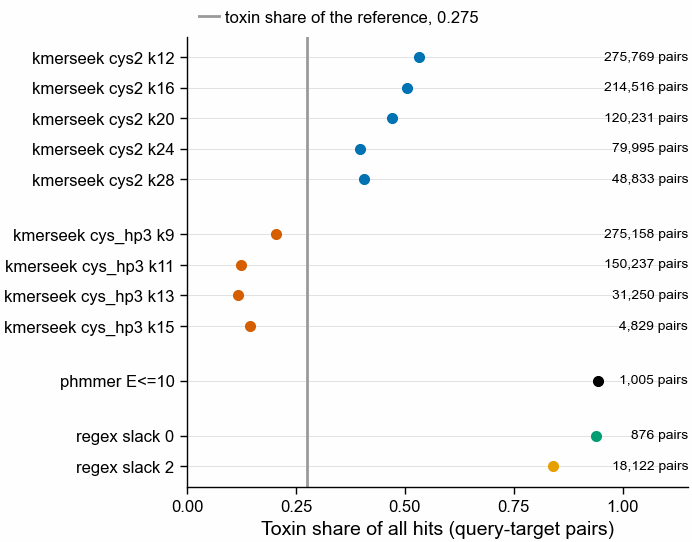

method,n_query_target_pairs,n_queries_with_hits,toxin_share_of_all_hits
str,i64,i64,f64
"""kmerseek cys2 k12""",275769,58,0.532
"""kmerseek cys2 k16""",214516,59,0.504
"""kmerseek cys2 k20""",120231,54,0.47
"""kmerseek cys2 k24""",79995,48,0.398
"""kmerseek cys2 k28""",48833,45,0.407
"""kmerseek cys_hp3 k9""",275158,59,0.205
"""kmerseek cys_hp3 k11""",150237,59,0.124
"""kmerseek cys_hp3 k13""",31250,56,0.118
"""kmerseek cys_hp3 k15""",4829,46,0.144


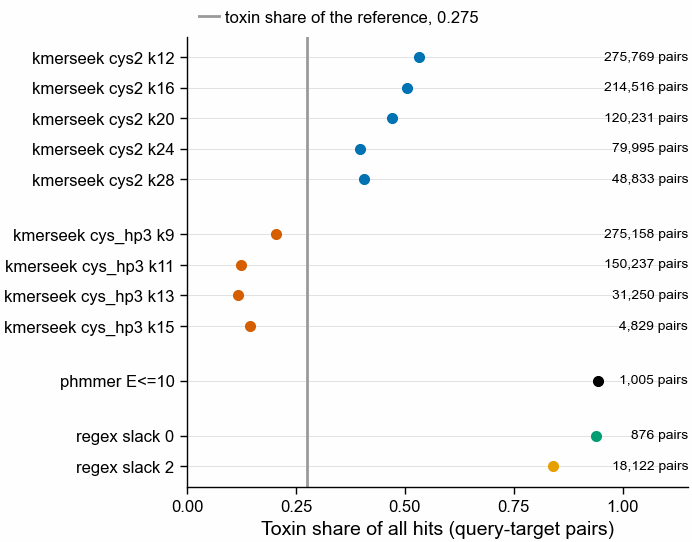

In [2]:
def kmerseek_hits(alphabet: str, ksize: int) -> pl.DataFrame:
    # One row per query and target, ranked within the query; see the markdown above.
    return (
        pl.read_parquet(DATA / f"phylum.{CLADE}.{alphabet}.k{ksize}.pairs.parquet")
        .filter(pl.col("target_accession").is_in(list(reference)))
        .sort(
            [
                "query_id",
                "best_region_poisson_score",
                "n_shared_kmers",
                "target_accession",
            ],
            descending=[False, True, True, False],
        )
        .with_columns(rank=pl.int_range(1, pl.len() + 1).over("query_id"))
    )


def phmmer_hits() -> pl.DataFrame:
    rows = []
    for line in open(DATA / f"phmmer/phylum.{CLADE}.phmmer.tbl"):
        if line.startswith("#"):
            continue
        f = line.split()
        rows.append((f[2], f[0].split("|")[1], float(f[4])))
    return (
        pl.DataFrame(
            rows, schema=["query_id", "target_accession", "evalue"], orient="row"
        )
        .filter(pl.col("target_accession").is_in(list(reference)))
        .group_by("query_id", "target_accession")
        .agg(pl.col("evalue").min())
        .filter(pl.col("evalue") <= PHMMER_MAX_EVALUE)
        .sort(["query_id", "evalue", "target_accession"])
        .with_columns(rank=pl.int_range(1, pl.len() + 1).over("query_id"))
    )


def regex_hits(slack: int) -> pl.DataFrame:
    return (
        pl.read_csv(DATA / f"regex/phylum.{CLADE}.regex.d{slack}.hits.csv")
        .filter(pl.col("target_accession").is_in(list(reference)))
        .unique(["query_id", "target_accession"])
    )


TOOLS = {}
for row in SETTINGS.iter_rows(named=True):
    TOOLS[f"kmerseek {row['alphabet']} k{row['ksize']}"] = (
        "kmerseek",
        row["alphabet"],
        row["ksize"],
        kmerseek_hits(row["alphabet"], row["ksize"]),
    )
TOOLS[f"phmmer E<={PHMMER_MAX_EVALUE}"] = ("phmmer", None, None, phmmer_hits())
for slack in (0, 2):
    TOOLS[f"regex slack {slack}"] = ("regex", None, slack, regex_hits(slack))

rows = []
for name, (tool, alphabet, k, hits) in TOOLS.items():
    tox = hits["target_accession"].is_in(list(truth))
    rows.append(
        {
            "method": name,
            "n_query_target_pairs": hits.height,
            "n_queries_with_hits": hits["query_id"].n_unique(),
            "toxin_share_of_all_hits": round(float(tox.mean()), 3),
        }
    )
overview = pl.DataFrame(rows)
print(f"toxin share of the reference itself: {base_rate:.3f}")

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
y = method_rows(overview["method"].to_list())
ax.axvline(
    base_rate,
    color=COLOUR["chance"],
    lw=1,
    label=f"toxin share of the reference, {base_rate:.3f}",
)
for yi, row in zip(y, overview.iter_rows(named=True)):
    ax.axhline(yi, color="#dddddd", lw=0.3, zorder=0)
    ax.plot(
        row["toxin_share_of_all_hits"],
        yi,
        "o",
        color=method_colour(row["method"]),
        ms=3,
    )
    ax.annotate(
        f"{row['n_query_target_pairs']:,} pairs",
        (1.0, yi),
        xycoords=("axes fraction", "data"),
        ha="right",
        va="center",
        fontsize=5,
    )
ax.set_yticks(y, overview["method"].to_list())
ax.set_xlim(0, 1.15)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_xlabel("Toxin share of all hits (query-target pairs)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False)
pf.save(
    fig,
    FIG / "296_toxin_share_of_all_hits_by_tool_cnidaria_pilot_swissprot",
    formats=("pdf", "png"),
)
display(fig)
overview

## 2. Toxins among each query's top 10 hits

For each query and tool: how many of the top 10 hits are toxins (0 to 10). The figure
shows the mean over the 59 queries with a 95% bootstrap interval (queries resampled with
replacement, 10,000 draws). Higher is better. The grey line is chance, 2.75. kmerseek is
drawn against k; phmmer and the two regexes have no k and are drawn as flat lines across
the panel.

These intervals resample individual queries. Related toxin peptides are not independent,
so these intervals do not measure uncertainty across independent protein families.
The means describe this query set; generalization to new families needs family-level resampling.


In [3]:
qids = queries["query_id"].to_list()


def expected_toxins(
    scored: pl.DataFrame, key: list[str], descending: list[bool]
) -> pl.DataFrame:
    # Expected toxins in each query's top TOP_N, ties broken at random (see section 1).
    groups = (
        scored.group_by(["query_id", *key])
        .agg(n=pl.len().cast(pl.Int64), t=pl.col("toxin").sum().cast(pl.Int64))
        .sort(["query_id", *key], descending=[False, *descending])
        .with_columns(before=(pl.col("n").cum_sum() - pl.col("n")).over("query_id"))
    )
    return (
        groups.with_columns(
            slots=pl.min_horizontal(pl.col("n"), pl.lit(TOP_N) - pl.col("before")).clip(
                0
            )
        )
        .with_columns(v=pl.col("slots") * pl.col("t") / pl.col("n"))
        .group_by("query_id")
        .agg(pl.col("v").sum())
    )


def toxins_in_top(
    name: str, toxins: set[str] = truth, removed: set[str] = frozenset()
) -> dict[str, float]:
    # `removed` are reference entries taken out before ranking (section 2b).
    tool, _, _, hits = TOOLS[name]
    if removed:
        hits = hits.filter(~pl.col("target_accession").is_in(list(removed)))
    hits = hits.with_columns(toxin=pl.col("target_accession").is_in(list(toxins)))
    if tool == "regex":
        per = expected_toxins(hits.with_columns(tie=pl.lit(0)), ["tie"], [False])
    elif tool == "phmmer":
        per = expected_toxins(hits, ["evalue"], [False])
    else:
        per = expected_toxins(
            hits, ["best_region_poisson_score", "n_shared_kmers"], [True, True]
        )
    got = dict(zip(per["query_id"], per["v"].cast(pl.Float64)))
    return {q: got.get(q, 0.0) for q in qids}


per_query = {name: toxins_in_top(name) for name in TOOLS}
summary_rows = []
for name, (tool, alphabet, k, _) in TOOLS.items():
    values = list(per_query[name].values())
    mean, lo, hi = cfu.bootstrap_ci(values)
    summary_rows.append(
        {
            "method": name,
            "tool": tool,
            "alphabet": alphabet,
            "k_or_slack": k,
            "mean_toxins_in_top10": round(mean, 2),
            "ci95_low": round(lo, 2),
            "ci95_high": round(hi, 2),
            "n_queries_no_toxin_in_top10": sum(v == 0 for v in values),
        }
    )
summary = pl.DataFrame(summary_rows).join(overview, on="method")
summary.select(
    "method",
    "mean_toxins_in_top10",
    "ci95_low",
    "ci95_high",
    "n_queries_no_toxin_in_top10",
    "n_queries_with_hits",
)

method,mean_toxins_in_top10,ci95_low,ci95_high,n_queries_no_toxin_in_top10,n_queries_with_hits
str,f64,f64,f64,i64,i64
"""kmerseek cys2 k12""",4.91,4.07,5.75,11,58
"""kmerseek cys2 k16""",5.03,4.21,5.86,3,59
"""kmerseek cys2 k20""",4.91,4.06,5.76,8,54
"""kmerseek cys2 k24""",4.01,3.04,5.0,15,48
"""kmerseek cys2 k28""",4.37,3.27,5.42,19,45
"""kmerseek cys_hp3 k9""",3.77,2.91,4.67,12,59
"""kmerseek cys_hp3 k11""",4.0,3.06,4.95,11,59
"""kmerseek cys_hp3 k13""",3.47,2.57,4.43,15,56
"""kmerseek cys_hp3 k15""",2.08,1.23,3.03,32,46


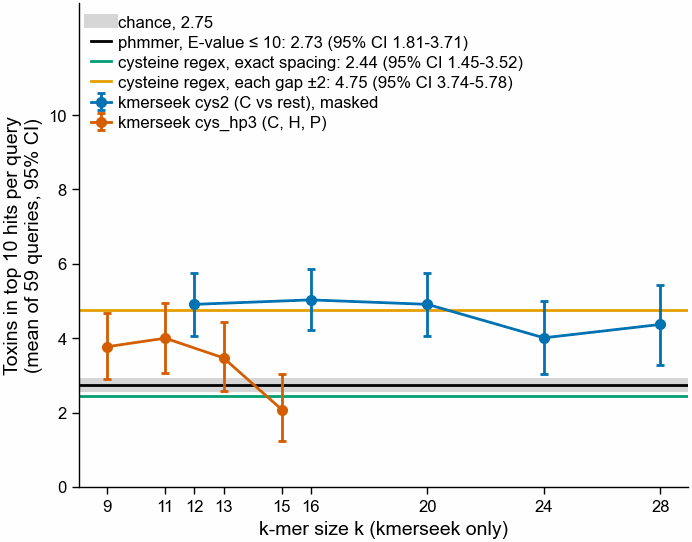

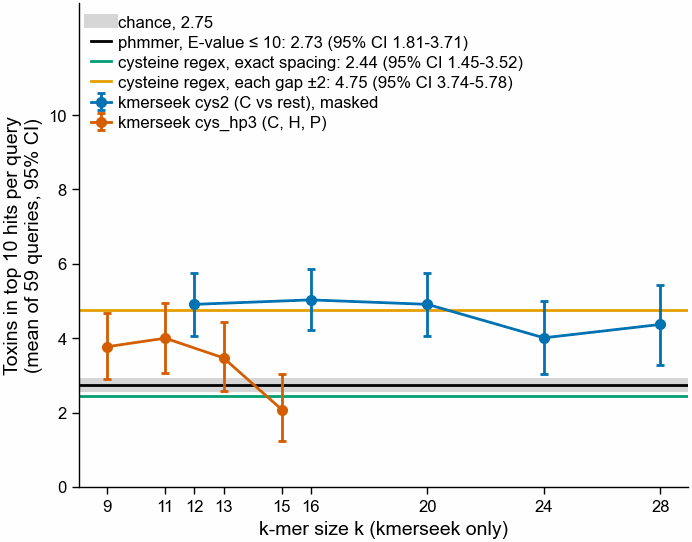

In [4]:
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
# Chance (2.75) and phmmer (2.73) nearly coincide: chance is drawn first as a wide pale
# band and phmmer as a thin line on top, so both stay visible.
ax.axhline(
    chance_top_n,
    color=COLOUR["chance"],
    lw=5,
    alpha=0.4,
    label=f"chance, {chance_top_n:.2f}",
)
for name, label, key in (
    (
        f"phmmer E<={PHMMER_MAX_EVALUE}",
        f"phmmer, E-value ≤ {PHMMER_MAX_EVALUE}",
        "phmmer",
    ),
    ("regex slack 0", "cysteine regex, exact spacing", "regex slack 0"),
    ("regex slack 2", "cysteine regex, each gap ±2", "regex slack 2"),
):
    r = summary.filter(pl.col("method") == name).row(0, named=True)
    ax.axhline(
        r["mean_toxins_in_top10"],
        color=COLOUR[key],
        lw=1,
        label=f"{label}: {r['mean_toxins_in_top10']:.2f} (95% CI {r['ci95_low']:.2f}-{r['ci95_high']:.2f})",
    )
for alphabet, label in (
    ("cys2", "kmerseek cys2 (C vs rest), masked"),
    ("cys_hp3", "kmerseek cys_hp3 (C, H, P)"),
):
    s = summary.filter(pl.col("alphabet") == alphabet).sort("k_or_slack")
    k = s["k_or_slack"].to_numpy()
    m = s["mean_toxins_in_top10"].to_numpy()
    ax.errorbar(
        k,
        m,
        yerr=[m - s["ci95_low"].to_numpy(), s["ci95_high"].to_numpy() - m],
        color=COLOUR[alphabet],
        marker="o",
        ms=3,
        capsize=1.5,
        label=label,
    )
ax.set_xlabel("k-mer size k (kmerseek only)")
ax.set_ylabel(
    f"Toxins in top {TOP_N} hits per query\n(mean of {len(qids)} queries, 95% CI)"
)
ax.set_xticks(sorted(SETTINGS["ksize"].unique().to_list()))
ax.set_ylim(0, TOP_N)
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.0), ncol=1, frameon=False)
ax.set_ylim(0, 13)
ax.set_yticks(range(0, TOP_N + 1, 2))
path = FIG / "296_toxins_in_top10_by_tool_cnidaria_pilot_swissprot"
pf.save(fig, path, formats=("pdf", "png"))
fig

**How to read it.** Each blue or red point is one kmerseek setting; the flat lines are the
tools that have no k. A point above the black line means kmerseek puts more toxins in a
query's top 10 than phmmer does. A point on the grey line means kmerseek's top 10 is no
better than 10 entries picked at random from the target database.

## 2b. The same count at the full reference's toxin share

The pilot reference is 27.5% toxins. The full Cnidaria-removed reference of the phylum run
(`run-phylum`, 2026-10-16) has 7,581 toxins among 575,042 entries, 1.32%. A tool whose top
10 is only weakly enriched for toxins gains a lot from a toxin-rich reference; a precise
tool gains little. To see each tool at the full share, keep a random 267 of the 7,581
toxins and remove the rest from the reference before ranking: 267 / (267 + 19,989) is
1.32%. The other 19,989 entries were drawn at random from Swiss-Prot's non-toxins, so they
stand in for the full reference's. Twenty such draws; the table gives the mean over draws
and the lowest and highest draw. Chance is now 0.13 toxins in 10.

This is an estimate, not the full run: a query's top 10 in 575,042 entries meets 29 times
more non-toxins than here, and only the full run shows how many of them outscore a toxin.

full reference: 7_581 toxins in 575_042 entries (1.32%); keep 267 of 7_581 toxins with the 19_989 non-toxins


chance at this share: 0.132 toxins in 10


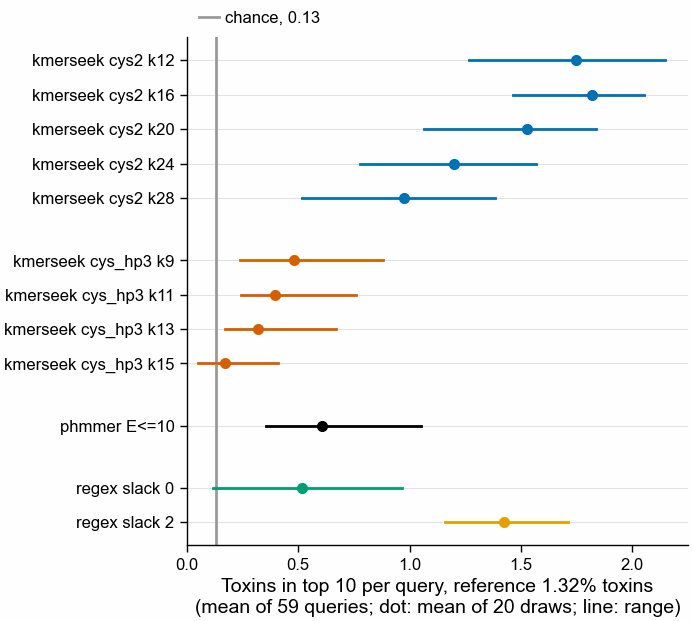

method,mean_toxins_in_top10,lowest_draw,highest_draw,times_chance
str,f64,f64,f64,f64
"""kmerseek cys2 k12""",1.747,1.268,2.147,13.3
"""kmerseek cys2 k16""",1.818,1.466,2.055,13.8
"""kmerseek cys2 k20""",1.526,1.063,1.836,11.6
"""kmerseek cys2 k24""",1.198,0.778,1.567,9.1
"""kmerseek cys2 k28""",0.975,0.519,1.383,7.4
"""kmerseek cys_hp3 k9""",0.479,0.237,0.881,3.6
"""kmerseek cys_hp3 k11""",0.395,0.243,0.759,3.0
"""kmerseek cys_hp3 k13""",0.32,0.169,0.668,2.4
"""kmerseek cys_hp3 k15""",0.17,0.051,0.407,1.3


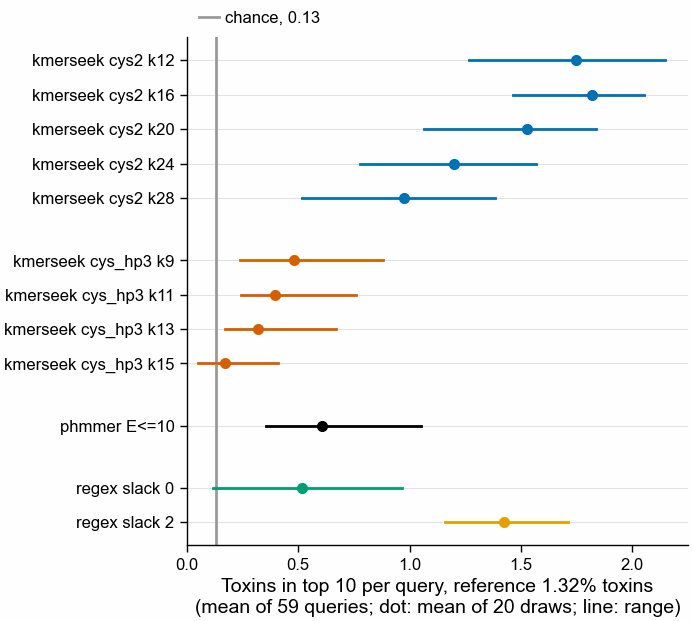

In [5]:
full_counts = pl.read_csv(
    DATA / f"full_reference_counts/counts.phylum.{CLADE}.tsv", separator="\t"
).row(0, named=True)
full_share = full_counts["n_toxins_left"] / full_counts["n_reference"]
non_toxins = len(reference - truth)
n_keep = round(non_toxins * full_share / (1 - full_share))
print(
    f"full reference: {full_counts['n_toxins_left']:_} toxins in {full_counts['n_reference']:_} entries ({full_share:.2%}); "
    f"keep {n_keep} of {len(truth & reference):_} toxins with the {non_toxins:_} non-toxins"
)
toxin_list = sorted(truth & reference)
draw_rng = np.random.default_rng(1)
draws = []
for draw in range(20):
    keep = set(draw_rng.choice(toxin_list, n_keep, replace=False))
    removed = (truth & reference) - keep
    for name in TOOLS:
        values = list(toxins_in_top(name, keep, removed).values())
        draws.append({"method": name, "draw": draw, "mean": float(np.mean(values))})
chance_full = TOP_N * n_keep / (n_keep + non_toxins)
at_full_share = (
    pl.DataFrame(draws)
    .group_by("method", maintain_order=True)
    .agg(
        mean_toxins_in_top10=pl.col("mean").mean().round(3),
        lowest_draw=pl.col("mean").min().round(3),
        highest_draw=pl.col("mean").max().round(3),
    )
    .with_columns(times_chance=(pl.col("mean_toxins_in_top10") / chance_full).round(1))
)
print(f"chance at this share: {chance_full:.3f} toxins in {TOP_N}")

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 80)
order = at_full_share["method"].to_list()
colour = [method_colour(m) for m in order]
y = method_rows(order)
ax.axvline(
    chance_full, color=COLOUR["chance"], lw=1, label=f"chance, {chance_full:.2f}"
)
for yi, row, c in zip(y, at_full_share.iter_rows(named=True), colour):
    ax.axhline(yi, color="#dddddd", lw=0.3, zorder=0)
    ax.plot([row["lowest_draw"], row["highest_draw"]], [yi, yi], color=c, lw=1)
    ax.plot(row["mean_toxins_in_top10"], yi, "o", color=c, ms=3)
ax.set_yticks(y, order)
ax.set_xlabel(
    f"Toxins in top {TOP_N} per query, reference 1.32% toxins\n"
    f"(mean of {len(qids)} queries; dot: mean of 20 draws; line: range)"
)
ax.set_xlim(0, None)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False)
path = (
    FIG / "296_toxins_in_top10_at_full_reference_toxin_share_cnidaria_pilot_swissprot"
)
pf.save(fig, path, formats=("pdf", "png"))
display(fig)
at_full_share

## 3. Query by query: does kmerseek find toxins where phmmer finds none?

The mean can hide a split: phmmer could be strong on half the queries and silent on the
rest, with kmerseek filling the gap. Each point is one query: its toxins in phmmer's top
10 (x) against its toxins in the top 10 of the kmerseek setting with the highest mean in
section 2 (y). Points are moved apart a little so equal values do not hide each other.

best kmerseek setting by mean: kmerseek cys2 k16
queries with no toxin in phmmer's top 10: 27 of 59
  of those, kmerseek cys2 k16 puts at least 1 toxin in its top 10: 21; at least 5: 8; mean 4.04 (chance 2.75)
queries where kmerseek beats phmmer: 37, ties: 13, phmmer ahead: 9


query_id,phmmer,kmerseek,framework,peptide_length
str,f64,f64,str,i64
"""sp:P86466""",0.0,0.0,"""C-C-CC""",27
"""sp:Q3C258""",0.0,0.0,"""C-C-C-C-C-C-C-C""",50
"""sp:Q3C257""",0.0,0.0,"""C-C-C-C-C-C-C-C""",52
"""sp:A0A0P0UTQ7""",0.0,0.204545,"""C-C-C-C""",28
"""sp:A0A0P0UTI6""",0.0,0.204545,"""C-C-C-C""",27
"""sp:A0A1R3S3A8""",0.0,0.428571,"""C-C-C-C""",35
"""sp:P0DY24""",0.0,1.346154,"""C-C-C-C""",30
"""sp:A0A0P0UTJ1""",0.0,1.346154,"""C-C-C-C""",30
"""sp:P0DMZ2""",0.0,2.0,"""CC-C-C-C-C-C-C""",31


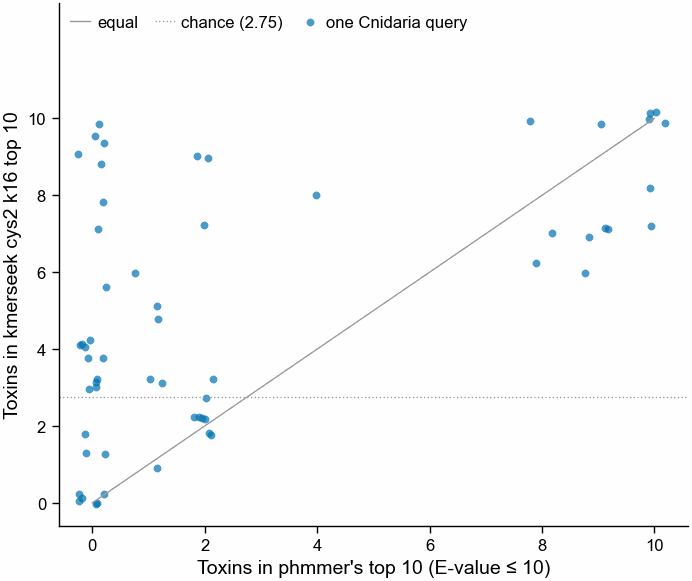

In [6]:
best = (
    summary.filter(pl.col("tool") == "kmerseek")
    .sort("mean_toxins_in_top10", descending=True)
    .row(0, named=True)
)
best_name = best["method"]
ph_name = f"phmmer E<={PHMMER_MAX_EVALUE}"
pair = pl.DataFrame(
    {
        "query_id": qids,
        "phmmer": [per_query[ph_name][q] for q in qids],
        "kmerseek": [per_query[best_name][q] for q in qids],
    }
).join(queries.select("query_id", "framework", "peptide_length"), on="query_id")
phmmer_silent = pair.filter(pl.col("phmmer") == 0)
print(f"best kmerseek setting by mean: {best_name}")
print(
    f"queries with no toxin in phmmer's top {TOP_N}: {phmmer_silent.height} of {pair.height}"
)
print(
    f"  of those, {best_name} puts at least 1 toxin in its top {TOP_N}: "
    f"{(phmmer_silent['kmerseek'] >= 1).sum()}; at least 5: {(phmmer_silent['kmerseek'] >= 5).sum()}; "
    f"mean {phmmer_silent['kmerseek'].mean():.2f} (chance {chance_top_n:.2f})"
)
print(
    f"queries where kmerseek beats phmmer: {(pair['kmerseek'] > pair['phmmer']).sum()}, "
    f"ties: {(pair['kmerseek'] == pair['phmmer']).sum()}, phmmer ahead: {(pair['kmerseek'] < pair['phmmer']).sum()}"
)

rng = np.random.default_rng(0)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 75)
ax.plot([0, TOP_N], [0, TOP_N], color=pf.GREY, lw=0.5, label="equal")
ax.axhline(
    chance_top_n, color=pf.GREY, lw=0.5, ls=":", label=f"chance ({chance_top_n:.2f})"
)
ax.scatter(
    pair["phmmer"] + rng.uniform(-0.25, 0.25, pair.height),
    pair["kmerseek"] + rng.uniform(-0.25, 0.25, pair.height),
    s=8,
    color=COLOUR[best["alphabet"]],
    alpha=0.7,
    lw=0,
    label="one Cnidaria query",
)
ax.set_xlabel(f"Toxins in phmmer's top {TOP_N} (E-value ≤ {PHMMER_MAX_EVALUE})")
ax.set_ylabel(
    f"Toxins in kmerseek {best['alphabet']} k{best['k_or_slack']} top {TOP_N}"
)
ax.set_xlim(-0.6, TOP_N + 0.6)
ax.set_ylim(-0.6, TOP_N + 3)
ax.set_xticks(range(0, TOP_N + 1, 2))
ax.set_yticks(range(0, TOP_N + 1, 2))
ax.legend(loc="upper left", frameon=False, ncol=3)
path = (
    FIG
    / f"296_per_query_phmmer_vs_kmerseek_{best['alphabet']}_k{best['k_or_slack']}_cnidaria_pilot_swissprot"
)
pf.save(fig, path, formats=("pdf", "png"))
pair.sort(["phmmer", "kmerseek"])

## 4. One query's top 10, with names and residues

The query below is the one phmmer finds no toxin for and the best kmerseek setting finds
the most toxins for (ties go to the longer peptide). Its top 10 under that setting is
listed with the target's Swiss-Prot name and the residues of the best matching region,
query above target; then the same query's phmmer hits.

query sp:P0DUG3, Urticina crassicornis (Mottled anemone) (Tealia crassicornis), framework C-C-C-C, 34 aa
  GASCDCHPFKGTYWFGTSNCPSGHGYRKKCDSFF

the three highest kmerseek score groups for this query (targets tied on score):
shape: (3, 4)
┌───────────────────────────┬────────────────┬───────────┬──────────┐
│ best_region_poisson_score ┆ n_shared_kmers ┆ n_targets ┆ n_toxins │
│ ---                       ┆ ---            ┆ ---       ┆ ---      │
│ f64                       ┆ i64            ┆ u32       ┆ u32      │
╞═══════════════════════════╪════════════════╪═══════════╪══════════╡
│ 5.089303                  ┆ 16             ┆ 1         ┆ 1        │
│ 5.089303                  ┆ 14             ┆ 8         ┆ 8        │
│ 5.089303                  ┆ 12             ┆ 2         ┆ 2        │
└───────────────────────────┴────────────────┴───────────┴──────────┘

kmerseek cys2 k16 top 10 (within a tie, by accession; the count in section 2 uses the tie's toxin share):
 1 B0L0Y6     toxin score 

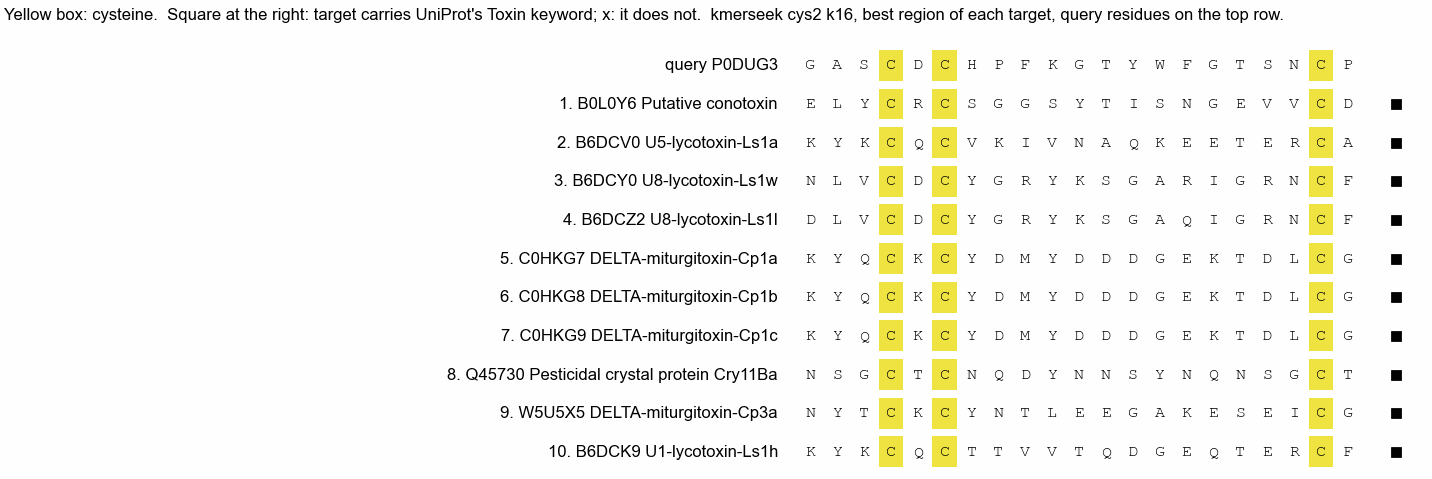


phmmer hits at E-value <= 10: 0


query_id,target_accession,evalue,rank,name
str,str,f64,i64,str


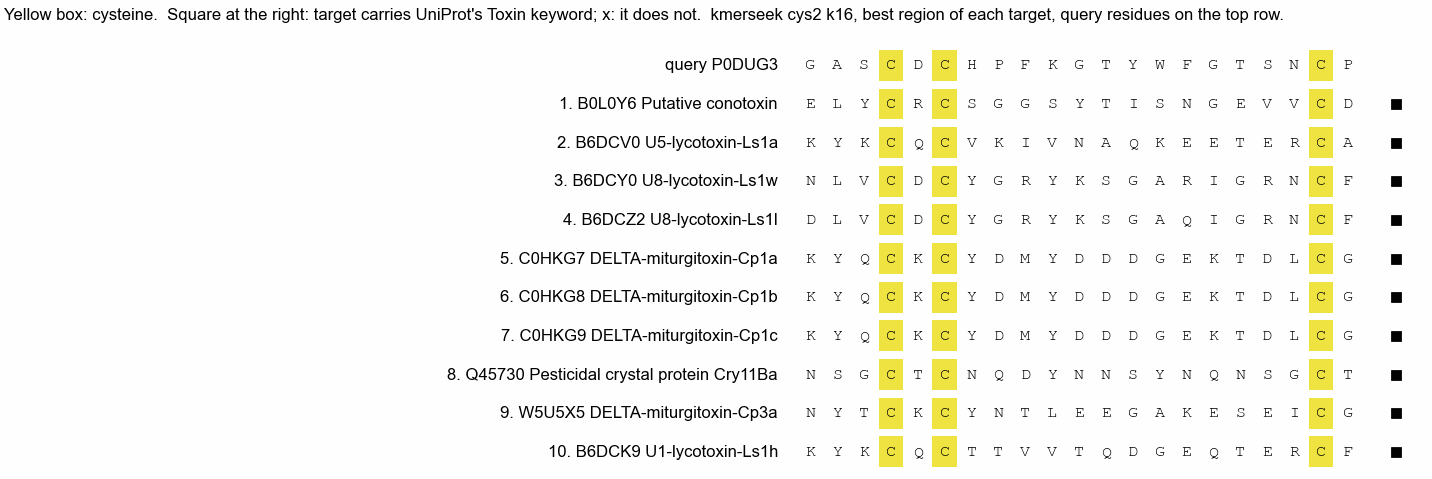

In [7]:
names = {}
want = reference
with gzip.open(SWISSPROT, "rt") as handle:
    for line in handle:
        if line.startswith(">"):
            acc = line.split("|")[1]
            if acc in want:
                names[acc] = line[1:].split(" ", 1)[1].split(" OS=")[0]

example = phmmer_silent.sort(["kmerseek", "peptide_length"], descending=True).row(
    0, named=True
)
qid = example["query_id"]
qrow = queries.filter(pl.col("query_id") == qid).row(0, named=True)
print(
    f"query {qid}, {qrow['organism']}, framework {qrow['framework']}, {qrow['peptide_length']} aa"
)
print(f"  {qrow['peptide']}")
top = (
    TOOLS[best_name][3]
    .filter((pl.col("query_id") == qid) & (pl.col("rank") <= TOP_N))
    .with_columns(
        toxin=pl.col("target_accession").is_in(list(truth)),
        name=pl.col("target_accession").replace_strict(names, default=""),
    )
    .select(
        "rank",
        "target_accession",
        "toxin",
        "name",
        "best_region_poisson_score",
        "n_shared_kmers",
        "best_region_subseq",
        "best_target_subseq",
    )
)
tied = (
    TOOLS[best_name][3]
    .filter(pl.col("query_id") == qid)
    .with_columns(toxin=pl.col("target_accession").is_in(list(truth)))
    .group_by("best_region_poisson_score", "n_shared_kmers")
    .agg(n_targets=pl.len(), n_toxins=pl.col("toxin").sum())
    .sort("best_region_poisson_score", "n_shared_kmers", descending=True)
    .head(3)
)
print(
    "\nthe three highest kmerseek score groups for this query (targets tied on score):"
)
print(tied)
print(
    f"\n{best_name} top {TOP_N} (within a tie, by accession; the count in section 2 uses the tie's toxin share):"
)
for r in top.iter_rows(named=True):
    print(
        f"{r['rank']:>2} {r['target_accession']:<10} {'toxin' if r['toxin'] else '-':<5} "
        f"score {r['best_region_poisson_score']:.2f}  {r['name'][:60]}"
    )
    print(f"     query  {r['best_region_subseq']}")
    print(f"     target {r['best_target_subseq']}")
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 62)
rows_drawn = [("query " + qid.split(":")[1], top["best_region_subseq"][0], None)] + [
    (
        f"{r['rank']}. {r['target_accession']} {r['name'][:38]}",
        r["best_target_subseq"],
        r["toxin"],
    )
    for r in top.iter_rows(named=True)
]
for i, (label, seq, toxin) in enumerate(rows_drawn):
    yi = -i
    for j, aa in enumerate(seq):
        if aa == "C":
            ax.add_patch(
                plt.Rectangle(
                    (j - 0.45, yi - 0.4), 0.9, 0.8, color=pf.OKABE_ITO["yellow"], lw=0
                )
            )
        ax.text(j, yi, aa, ha="center", va="center", family="monospace", fontsize=6)
    ax.text(-1.2, yi, label, ha="right", va="center", fontsize=6)
    if toxin is not None:
        ax.plot(len(seq) + 0.8, yi, "s" if toxin else "x", color="black", ms=3)
ax.set_xlim(-30, max(len(r[1]) for r in rows_drawn) + 2)
ax.set_ylim(-len(rows_drawn) + 0.4, 1.6)
ax.axis("off")
ax.text(
    -30,
    1.3,
    "Yellow box: cysteine.  Square at the right: target carries UniProt's Toxin keyword; x: it does not.  "
    f"{best_name}, best region of each target, query residues on the top row.",
    fontsize=6,
    va="center",
)
pf.save(
    fig,
    FIG
    / f"296_example_{qid.split(':')[1]}_top10_regions_{best['alphabet']}_k{best['k_or_slack']}_cnidaria_pilot_swissprot",
    formats=("pdf", "png"),
)
display(fig)
ph = (
    TOOLS[ph_name][3]
    .filter(pl.col("query_id") == qid)
    .with_columns(name=pl.col("target_accession").replace_strict(names, default=""))
)
print(f"\nphmmer hits at E-value <= {PHMMER_MAX_EVALUE}: {ph.height}")
ph

## Summary and conclusions

**Verdict.** On the Cnidaria pilot, kmerseek `cys2` puts about twice as many toxins in a
query's top 10 as phmmer or the exact cysteine regex. But it does no better than a regex
that lets each gap between cysteines differ by up to 2 residues. `cys_hp3` is the weaker
of the two kmerseek alphabets at every k. By the decision rule the full runs go ahead.
Before the full run can say the k-mers add anything beyond the cysteine spacing, it has to
beat the slack-2 regex, and on this pilot it does not.

**Claims, each with its number.**

1. **kmerseek `cys2` k16 puts 5.03 toxins in a query's top 10 (95% CI 4.21-5.86), against
   2.73 for phmmer at E-value 10 (1.81-3.71) and 2.44 for the exact cysteine regex
   (1.45-3.52), over 59 Cnidaria queries against Swiss-Prot without Cnidaria.** The
   intervals do not overlap. Chance is 2.75. Higher is better. `cys2` at k 12 and 20 gives
   4.91, k24 4.01, k28 4.37.
2. **The cysteine regex with each gap allowed ±2 residues gives 4.75 (3.74-5.78), level
   with kmerseek `cys2`.** kmerseek's best matching regions are cysteine-spacing matches:
   for query P0DUG3, a sea-anemone C-C-C-C peptide, 11 targets tie at kmerseek's top score
   (5.09), all toxins. Their best regions share the query's cysteine spacing (two
   cysteines one residue apart, a third 14 residues later) and few other residues
   (section 4).
3. **`cys_hp3` (cysteine, hydrophobic, polar) is below `cys2` at every k: 3.77, 4.00, 3.47
   and 2.08 at k 9, 11, 13 and 15.** At k15 it is below chance. Most of `cys_hp3`'s hits
   are non-toxins: toxins are 12-21% of its hits in a reference that is 27.5% toxins.
4. **phmmer finds no toxin in its top 10 for 27 of the 59 queries; `cys2` k16 finds at
   least one for 21 of those 27, and at least 5 for 8.** Its mean on those 27 is 4.04
   against chance 2.75, so on the queries phmmer misses kmerseek is above chance but
   weakly. Query by query, `cys2` k16 beats phmmer on 37 queries, ties on 13 and loses on 9.
5. **At the full reference's toxin share (1.32% instead of 27.5%, estimated by dropping
   toxins at random), `cys2` k16 gives 1.82 toxins in 10 (draws 1.47-2.06), the slack-2
   regex 1.42 (1.16-1.71), phmmer 0.61 (0.36-1.05), and `cys_hp3` 0.17-0.48.** Chance is
   0.13. kmerseek `cys2` keeps a small lead over the slack-2 regex there, inside the
   spread of the draws.

**What the numbers do not show.** The truth is UniProt's Toxin keyword, which marks any
toxin, not a homolog with the same fold: a hit to a spider toxin with the query's cysteine
spacing counts as correct whether or not it shares the query's fold. Section 2b only
estimates the full reference. A real top 10 out of 575,042 entries meets 29 times more
non-toxins, and only the full run says how many outscore a toxin. The pilot had 59 queries
(at most 10 per framework); the full Cnidaria set has 235.

**Decisions.**

- Run `cys2` on the full references: it is the setting with the best pilot result, and
  it needs the kmerseek fit fix to index a full Swiss-Prot (seanome/kmerseek, the E-value
  fit's memory).
- The full run reports the slack-2 regex next to every kmerseek setting, query by query.
  The claim "k-mers add something beyond the cysteine spacing" needs `cys2` above that
  regex with intervals apart.
- `cys_hp3` is the weaker alphabet on this pilot. Its full run is cheap (no fix needed)
  and is worth keeping as the comparison, but it is not where a positive result is
  expected.